# Protein alignment with BLOSUM62

Score conservative substitutions in a local peptide alignment.

A substitution matrix encodes empirical exchange preferences. An affine gap separates the cost of starting a gap from the cost of extending it. Local alignment can leave unrelated ends uncovered.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from Bio.Align import PairwiseAligner, substitution_matrices

## Work through the data

The calculation prints its numerical result and plots the observations that produced it.

target            2 DKVILST 9
                  0 |||.||| 7
query             2 DKVVLST 9

alignment score 31.0


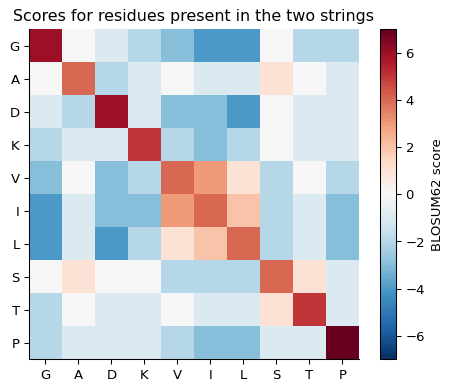

In [2]:
matrix = substitution_matrices.load("BLOSUM62")
alg = PairwiseAligner(mode="local")
alg.substitution_matrix = matrix
alg.open_gap_score = -10
alg.extend_gap_score = -1
a, b = "GADKVILST", "TTDKVVLSTP"
best = alg.align(a, b)[0]
print(best)
print("alignment score", best.score)
assert best.score == alg.score(a, b)
letters = list(dict.fromkeys(a + b))
values = np.array([[matrix[x, y] for y in letters] for x in letters])
fig, ax = plt.subplots(figsize=(5.4, 4), constrained_layout=True)
im = ax.imshow(values, cmap="RdBu_r", vmin=-7, vmax=7)
ax.set(
    xticks=range(len(letters)),
    yticks=range(len(letters)),
    xticklabels=letters,
    yticklabels=letters,
    title="Scores for residues present in the two strings",
)
fig.colorbar(im, ax=ax, label="BLOSUM62 score")
plt.show()

## Interpreting the result

The V/I substitution retains a positive score. The coloured matrix lets you inspect the contribution directly.

## Exercise

Compare the score of I→V with I→D while holding gaps and flanks fixed.

## References

[Henikoff and Henikoff, BLOSUM substitution matrices (1992)](https://doi.org/10.1073/pnas.89.22.10915)

[Biopython, substitution matrices and alignments](https://biopython.org/docs/latest/Tutorial/chapter_pairwise.html)